In [9]:
# library

import os
import cv2
import json
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm import tqdm

In [10]:
# ==========================================
# 1. 개별 품질 평가 지표 함수 (Metrics)
# ==========================================
def calculate_entropy(img: np.ndarray) -> float:
    hist, _ = np.histogram(img.ravel(), bins=256, range=(0, 256))
    hist = hist / hist.sum()
    non_zero_hist = hist[hist > 0]
    return float(-np.sum(non_zero_hist * np.log2(non_zero_hist)))

def calculate_contrast(img: np.ndarray) -> float:
    return float(np.std(img))

def calculate_edge_density(img: np.ndarray, low_thresh: int = 50, high_thresh: int = 150) -> float:
    edges = cv2.Canny(img, low_thresh, high_thresh)
    return float(np.count_nonzero(edges) / edges.size)

def calculate_laplacian_variance(img: np.ndarray) -> float:
    return float(cv2.Laplacian(img, cv2.CV_64F).var())

def calculate_brenner_focus(img: np.ndarray) -> float:
    # 이미지가 너무 작으면(가로 2픽셀 미만) Brenner 계산 불가
    if img.shape[1] < 3: 
        return 0.0
    x_diff = (img[:, 2:].astype(np.float64) - img[:, :-2].astype(np.float64)) ** 2
    return float(np.mean(x_diff))

# bounding box 크기가 너무 작으면 brenner focus 계산시, 배열 슬라이싱 시 크기가 맞지 않아 에러 발생
def get_all_metrics(img: np.ndarray) -> dict:
    """단일 이미지(또는 ROI)에 대해 모든 지표를 계산하여 딕셔너리로 반환"""
    # 이미지가 너무 작거나 비어있으면 0 반환 (예외 처리)
    if img is None or img.size == 0 or img.shape[0] < 3 or img.shape[1] < 3:
        return {"entropy": 0.0, "contrast": 0.0, "edge_density": 0.0, "laplacian_var": 0.0, "brenner_focus": 0.0}
        
    return {
        "entropy": calculate_entropy(img),
        "contrast": calculate_contrast(img),
        "edge_density": calculate_edge_density(img),
        "laplacian_var": calculate_laplacian_variance(img),
        "brenner_focus": calculate_brenner_focus(img),
    }

In [11]:
# ==========================================
# 2. COCO Annotation 로더
# ==========================================
# 시간 복잡도를 줄이기 위함

def load_coco_annotations(json_path: str) -> dict:
    with open(json_path, 'r') as f:
        coco_data = json.load(f)
        
    # image_id를 key로, 파일명을 value로 매핑
    image_dict = {img['id']: img['file_name'] for img in coco_data['images']}
    
    # 파일명을 key로, bbox 리스트를 value로 매핑 (한 이미지에 협착이 여러 개일 수 있음)
    bbox_dict = {img['file_name']: [] for img in coco_data['images']}
    for ann in coco_data['annotations']:
        img_id = ann['image_id']
        file_name = image_dict[img_id]
        bbox_dict[file_name].append(ann['bbox']) # [x, y, width, height]
        
    return bbox_dict

In [12]:
# ==========================================
# 3. Pipeline quality evaluation engine
# ==========================================

def evaluate_preprocessing_pipelines(
    data_root: Path,
    anno_path: Path,
    pipelines: list,
    original_dir: Path | None = None,
    split_name: str = "train",
) -> pd.DataFrame:
    # pipelines example: ["original", "01_clahe", "02_gamma", ...]
    # original: original_dir / <filename>
    # others  : data_root / pipeline / split_name / <filename>
    bbox_dict = load_coco_annotations(str(anno_path))
    results = []

    if "original" in pipelines:
        if original_dir is None:
            raise ValueError("pipelines includes original, but original_dir is None")
        list_dir = Path(original_dir)
    else:
        first = pipelines[0]
        list_dir = Path(data_root) / first / split_name

    image_files = sorted([f.name for f in list_dir.glob("*.png")])
    if len(image_files) == 0:
        raise FileNotFoundError(f"No png files found: {list_dir}")

    for img_name in tqdm(image_files, desc=f"Evaluating Pipelines ({split_name})"):
        bboxes = bbox_dict.get(img_name, [])

        for pipe in pipelines:
            if pipe == "original":
                img_path = Path(original_dir) / img_name
            else:
                img_path = Path(data_root) / pipe / split_name / img_name

            img = cv2.imread(str(img_path), cv2.IMREAD_GRAYSCALE)
            if img is None:
                print(f"Warning: Could not read {img_path}")
                continue

            global_metrics = get_all_metrics(img)

            roi_metrics_list = []
            for bbox in bboxes:
                x, y, w, h = [int(v) for v in bbox]
                x, y = max(0, x), max(0, y)
                w = min(w, img.shape[1] - x)
                h = min(h, img.shape[0] - y)
                roi = img[y:y+h, x:x+w]
                roi_metrics_list.append(get_all_metrics(roi))

            if len(roi_metrics_list) > 0:
                avg_roi_metrics = {
                    k: float(np.mean([m[k] for m in roi_metrics_list]))
                    for k in global_metrics.keys()
                }
            else:
                avg_roi_metrics = {k: 0.0 for k in global_metrics.keys()}

            row_data = {
                "image_name": img_name,
                "pipeline": pipe,
                "split": split_name,
                "bbox_count": len(bboxes),
            }
            row_data.update({f"global_{k}": v for k, v in global_metrics.items()})
            row_data.update({f"roi_{k}": v for k, v in avg_roi_metrics.items()})
            results.append(row_data)

    return pd.DataFrame(results)


In [13]:
# ==========================================
# 4. Paths + run
# ==========================================
PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "data"

# choose split to evaluate
# "train" or "val"
eval_split = "train"

RAW_TRAIN_DIR = DATA_DIR / "arcade" / "arcade" / "stenosis" / "train" / "images"
RAW_VAL_DIR = DATA_DIR / "arcade" / "arcade" / "stenosis" / "val" / "images"
ANNO_TRAIN = DATA_DIR / "arcade" / "arcade" / "stenosis" / "train" / "annotations" / "train.json"
ANNO_VAL = DATA_DIR / "arcade" / "arcade" / "stenosis" / "val" / "annotations" / "val.json"
PREPROCESS_DIR = DATA_DIR / "preprocessed"
OUT_CSV = Path.cwd() / f"preprocessing_quality_metrics_{eval_split}.csv"

if eval_split == "train":
    RAW_DIR = RAW_TRAIN_DIR
    ANNO_PATH = ANNO_TRAIN
else:
    RAW_DIR = RAW_VAL_DIR
    ANNO_PATH = ANNO_VAL

PIPELINES = [
    "original",
    "01_clahe",
    "02_gamma",
    "03_frangi",
    "04_clahe_gamma",
    "05_clahe_gamma_frangi",
    "06_gamma_clahe_frangi",
    "07_black_hat",
]

print("cwd            :", Path.cwd())
print("eval_split     :", eval_split)
print("RAW_DIR        :", RAW_DIR, "| exists:", RAW_DIR.exists())
print("ANNO_PATH      :", ANNO_PATH, "| exists:", ANNO_PATH.exists())
print("PREPROCESS_DIR :", PREPROCESS_DIR, "| exists:", PREPROCESS_DIR.exists())

for pipe in PIPELINES:
    if pipe == "original":
        p = RAW_DIR
    else:
        p = PREPROCESS_DIR / pipe / eval_split
    n = len(list(p.glob("*.png"))) if p.exists() else 0
    print(f"  {pipe:24s} -> {p} | png={n} | exists={p.exists()}")

assert RAW_DIR.exists(), f"RAW_DIR missing: {RAW_DIR}"
assert ANNO_PATH.exists(), f"ANNO_PATH missing: {ANNO_PATH}"
assert PREPROCESS_DIR.exists(), f"PREPROCESS_DIR missing: {PREPROCESS_DIR}"

df_results = evaluate_preprocessing_pipelines(
    data_root=PREPROCESS_DIR,
    anno_path=ANNO_PATH,
    pipelines=PIPELINES,
    original_dir=RAW_DIR,
    split_name=eval_split,
)

print(df_results.groupby("pipeline").mean(numeric_only=True))
df_results.to_csv(OUT_CSV, index=False)
print("saved:", OUT_CSV)


cwd            : <PROJECT_ROOT>/notebooks
eval_split     : train
RAW_DIR        : <PROJECT_ROOT>/data/arcade/arcade/stenosis/train/images | exists: True
ANNO_PATH      : <PROJECT_ROOT>/data/arcade/arcade/stenosis/train/annotations/train.json | exists: True
PREPROCESS_DIR : <PROJECT_ROOT>/data/preprocessed | exists: True
  original                 -> <PROJECT_ROOT>/data/arcade/arcade/stenosis/train/images | png=1000 | exists=True
  01_clahe                 -> <PROJECT_ROOT>/data/preprocessed/01_clahe/train | png=1000 | exists=True
  02_gamma                 -> <PROJECT_ROOT>/data/preprocessed/02_gamma/train | png=1000 | exists=True
  03_frangi                -> <PROJECT_ROOT>/data/preprocessed/03_frangi/train | png=1000 | exists=True
  04_clahe_gamma           -> <PROJECT_ROOT>/data/preprocessed/04_clahe_gamma/train | png=1000 | exists=True
  05_clahe_gamma_frangi    -> <PROJECT_ROOT>/data/preprocessed/05_clahe_gamma_frangi/train | png=1000 | exists=True
  06_gamma_clahe_frangi    -> <P

                       bbox_count  global_entropy  global_contrast  \
pipeline                                                             
01_clahe                    1.625        7.248269        44.132387   
02_gamma                    1.625        6.710501        37.385737   
03_frangi                   1.625        1.450660         6.751397   
04_clahe_gamma              1.625        7.102118        42.247377   
05_clahe_gamma_frangi       1.625        2.181978         7.478044   
06_gamma_clahe_frangi       1.625        2.217358         7.518191   
07_black_hat                1.625        4.427779        11.306424   
original                    1.625        6.846753        38.697224   

                       global_edge_density  global_laplacian_var  \
pipeline                                                           
01_clahe                          0.240746            548.082601   
02_gamma                          0.023785            260.728219   
03_frangi                  

In [14]:
# seaborn이 없으면 설치 (이미 있으면 스킵)
try:
    import seaborn as sns
    print("seaborn OK:", sns.__version__)
except ImportError:
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "seaborn"])
    import seaborn as sns
    print("seaborn installed:", sns.__version__)


seaborn OK: 0.13.2


Historical seaborn FutureWarning: palette without hue; see docs/reproducibility.md.


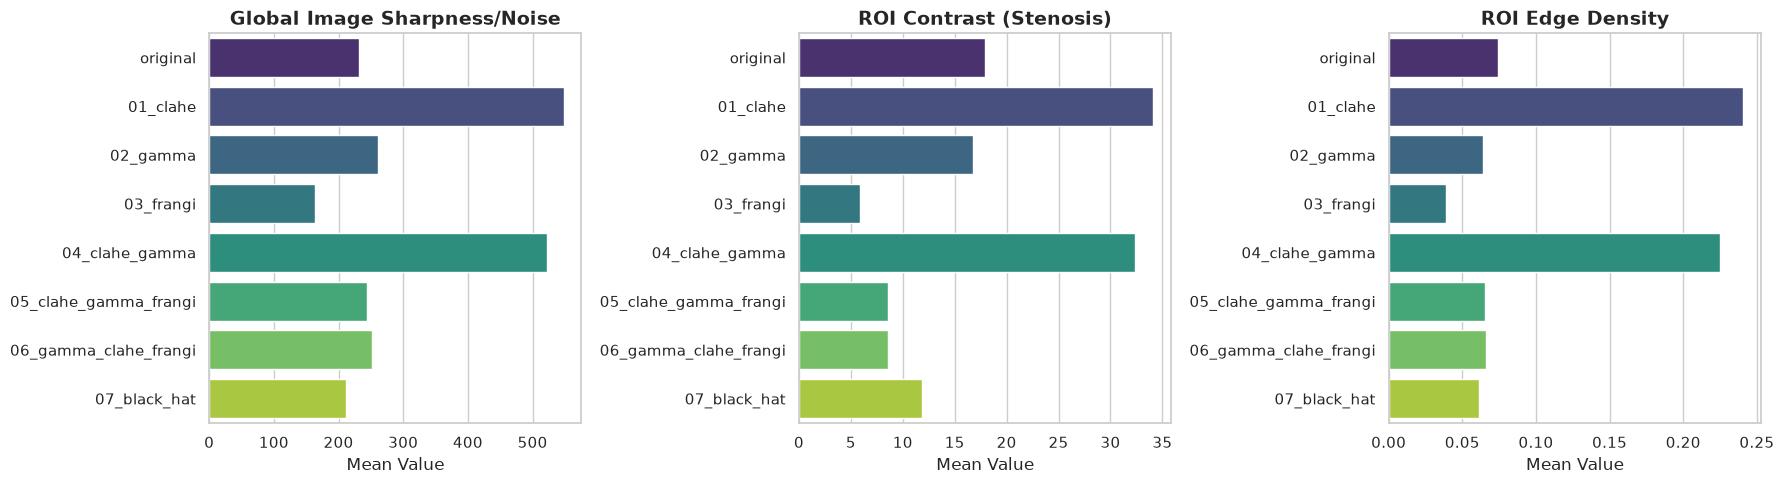

,pipeline,bbox_count,global_entropy,global_contrast,global_edge_density,global_laplacian_var,global_brenner_focus,roi_entropy,roi_contrast,roi_edge_density,roi_laplacian_var,roi_brenner_focus
7,original,1.625,6.846753,38.697224,0.026422,230.966124,79.514853,5.917155,17.958918,0.074510,124.903015,97.326902
0,01_clahe,1.625,7.248269,44.132387,0.240746,548.082601,251.485497,6.793286,34.135542,0.240672,542.166385,394.086953
1,02_gamma,1.625,6.710501,37.385737,0.023785,260.728219,81.115837,5.774372,16.764209,0.063751,110.409514,85.706464
2,03_frangi,1.625,1.450660,6.751397,0.015671,163.663771,45.370493,2.016651,5.876985,0.038967,249.932526,85.591779
3,04_clahe_gamma,1.625,7.102118,42.247377,0.217447,521.803766,227.543498,6.664163,32.315488,0.224897,479.316779,350.582378
4,05_clahe_gamma_frangi,1.625,2.181978,7.478044,0.029102,244.225845,68.544119,2.731847,8.565014,0.065175,421.854745,144.411336
5,06_gamma_clahe_frangi,1.625,2.217358,7.518191,0.030404,251.545937,70.649785,2.757397,8.620384,0.066283,430.055452,147.593928
6,07_black_hat,1.625,4.427779,11.306424,0.018557,211.706676,61.870278,5.003696,11.856169,0.061074,122.227509,80.905712


In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

csv_path = Path.cwd() / f"preprocessing_quality_metrics_{eval_split}.csv"
df = pd.read_csv(csv_path)

df_mean = df.groupby("pipeline").mean(numeric_only=True).reset_index()

pipe_order = [
    "original",
    "01_clahe",
    "02_gamma",
    "03_frangi",
    "04_clahe_gamma",
    "05_clahe_gamma_frangi",
    "06_gamma_clahe_frangi",
    "07_black_hat",
]
df_mean["pipeline"] = pd.Categorical(df_mean["pipeline"], categories=pipe_order, ordered=True)
df_mean = df_mean.sort_values("pipeline")

metrics_to_plot = ["global_laplacian_var", "roi_contrast", "roi_edge_density"]
titles = [
    "Global Image Sharpness/Noise",
    "ROI Contrast (Stenosis)",
    "ROI Edge Density",
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.set_theme(style="whitegrid")

for i, metric in enumerate(metrics_to_plot):
    sns.barplot(
        data=df_mean,
        x=metric,
        y="pipeline",
        ax=axes[i],
        palette="viridis",
        order=pipe_order,
    )
    axes[i].set_title(titles[i], fontsize=14, fontweight="bold")
    axes[i].set_xlabel("Mean Value")
    axes[i].set_ylabel("")

plt.tight_layout()
plt.show()

df_mean


## Usage
1. Run library / metrics / COCO loader cells
2. Run evaluation engine cell
3. Run paths + execution cell (`eval_split` = `train` or `val`)
4. Run seaborn check cell
5. Run plotting cell

Pipelines include `07_black_hat`.
Preprocessed path uses `data/preprocessed/{pipeline}/{split}/`.


In [ ]:
# Metric ranking summary (higher is better)
# Uses df_mean from the previous plotting cell.

import pandas as pd

rank_metrics = [
    'roi_contrast',
    'roi_edge_density',
    'global_laplacian_var',
    'roi_brenner_focus',
]

missing = [m for m in rank_metrics if m not in df_mean.columns]
if missing:
    print('Missing metrics in df_mean:', missing)

available_metrics = [m for m in rank_metrics if m in df_mean.columns]

summary_tables = []
for metric in available_metrics:
    t = df_mean[['pipeline', metric]].copy()
    t = t.sort_values(metric, ascending=False).reset_index(drop=True)
    t['rank'] = t.index + 1
    t = t[['rank', 'pipeline', metric]]
    summary_tables.append((metric, t))

for metric, t in summary_tables:
    print('' + '=' * 70)
    print(f'Metric: {metric} (desc)')
    print(t.to_string(index=False))

# composite score (equal-weight rank average)
if available_metrics:
    rank_df = pd.DataFrame({'pipeline': df_mean['pipeline'].astype(str)})
    for metric in available_metrics:
        rank_df[f'rank_{metric}'] = df_mean[metric].rank(ascending=False, method='min')

    rank_cols = [c for c in rank_df.columns if c.startswith('rank_')]
    rank_df['rank_mean'] = rank_df[rank_cols].mean(axis=1)
    rank_df = rank_df.sort_values('rank_mean').reset_index(drop=True)
    rank_df['overall_rank'] = rank_df.index + 1

    print('' + '=' * 70)
    print('Overall rank (mean of metric ranks, lower is better)')
    print(rank_df[['overall_rank', 'pipeline', 'rank_mean'] + rank_cols].to_string(index=False))

rank_df if 'rank_df' in locals() else None
